# Week 10 Project Starter Template: Recommender Pipeline
**Team name:** Movie Finder

| **Members:** K V Sanjana Priya, S Aparna

| **Topic (ID and name):**  P01,Movie Recommendation system

| **Twist (if sharing a topic):** ____________

How to use this: keep the section order, fill every TODO, delete this instruction block when done. AI tools are allowed. Every number you report must come from running this notebook. Sections 12 to 14 are the **understanding pack**, which is what shows the project is yours.

| # | Section | Done |
|---|---|---|
| 1 | Problem and users | [ ] |
| 2 | Data | [ ] |
| 3 | EDA | [ ] |
| 4 | Baselines | [ ] |
| 5 | Content-based model | [ ] |
| 6 | Collaborative model | [ ] |
| 7 | Matrix factorization (SVD) | [ ] |
| 8 | Honest evaluation and results table | [ ] |
| 9 | Cold start or hybrid | [ ] |
| 10 | Demo: recommend() | [ ] |
| 11 | Break-it tests | [ ] |
| 12 | By-hand check | [ ] |
| 13 | Deliberate-leak experiment, decision log, bug log | [ ] |
| 14 | AI-use log | [ ] |

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ml-latest-small.zip to ml-latest-small (1).zip


In [ ]:
import zipfile
import os
zip_path = "/content/ml-latest-small.zip"
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/")
data_folder = "/content/ml-latest-small"
print("Dataset extracted:", os.path.exists(data_folder))
print("Files found:", os.listdir(data_folder))

Dataset extracted: True
Files found: ['links.csv', 'ratings.csv', 'movies.csv', 'README.txt', 'tags.csv']


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
np.random.seed(1)
pd.set_option('display.precision', 3)


In [ ]:
import os
data_folder = "/content/ml-latest-small"
print("Files:", os.listdir(data_folder))

Files: ['links.csv', 'ratings.csv', 'movies.csv', 'README.txt', 'tags.csv']


In [ ]:
movies = pd.read_csv(data_folder + "/movies.csv")
ratings = pd.read_csv(data_folder + "/ratings.csv")
tags = pd.read_csv(data_folder + "/tags.csv")
links = pd.read_csv(data_folder + "/links.csv")

print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)
print("Tags shape:", tags.shape)
print("Links shape:", links.shape)

Movies shape: (9742, 3)
Ratings shape: (100836, 4)
Tags shape: (3683, 4)
Links shape: (9742, 3)


In [ ]:

# Prepare ratings dataset consistently
ratings = pd.read_csv("/content/ml-latest-small/ratings.csv")
movies = pd.read_csv("/content/ml-latest-small/movies.csv")

df = ratings.rename(columns={
    "userId": "user",
    "movieId": "item",
    "timestamp": "time"
}).copy()

# Convert IDs to strings
df["user"] = df["user"].astype(str)
df["item"] = df["item"].astype(str)

print("Ratings shape:", df.shape)
print(df.head())
print("User ID type:", df["user"].dtype)
print("Movie ID type:", df["item"].dtype)


Ratings shape: (100836, 4)
  user item  rating       time
0    1    1     4.0  964982703
1    1    3     4.0  964981247
2    1    6     4.0  964982224
3    1   47     5.0  964983815
4    1   50     5.0  964982931
User ID type: object
Movie ID type: object


In [ ]:
print("MOVIES DATA:")
display(movies.head())

print("RATINGS DATA:")
display(ratings.head())

print("TAGS DATA:")
display(tags.head())

MOVIES DATA:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


RATINGS DATA:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


TAGS DATA:


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


In [ ]:
print("Missing values in Movies:")
print(movies.isnull().sum())

print("\nMissing values in Ratings:")
print(ratings.isnull().sum())

Missing values in Movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in Ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


In [ ]:
print("Movies Information:")
movies.info()

print("\nRatings Information:")
ratings.info()

Movies Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB

Ratings Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


## Helpers (tested, reuse them)
Ratings live in a **long table** with columns `user`, `item`, `rating` and optionally `time`. Rename your own columns to match.

In [ ]:

def split_ratings(df, test_frac=0.2, time_col=None, min_user_ratings=5, seed=1):
    """Split ratings into train and test sets."""
    rng = np.random.RandomState(seed)
    test_idx = []
    for u, g in df.groupby("user"):
        if len(g) < min_user_ratings:
            continue
        n_test = max(1, int(round(test_frac * len(g))))
        if time_col:
            test_idx += list(g.sort_values(time_col).index[-n_test:])
        else:
            test_idx += list(rng.choice(g.index, n_test, replace=False))

    test = df.loc[test_idx]
    train = df.drop(index=test_idx)
    return train.reset_index(drop=True), test.reset_index(drop=True)
def to_matrix(df, users=None, items=None):
    """Create a user-item matrix with 0 for missing ratings."""
    M = df.pivot_table(
        index="user",
        columns="item",
        values="rating",
        aggfunc="mean")
    if users is not None:
        M = M.reindex(index=users)

    if items is not None:
        M = M.reindex(columns=items)

    return M.fillna(0.0).astype(float)

def rmse(pred, true):
    pred = np.asarray(pred, dtype=float)
    true = np.asarray(true, dtype=float)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

def precision_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / k

def recall_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / max(1, len(relevant))

def ndcg_at_k(recommended, relevant, k):
    relevant = set(relevant)

    gains = [
        1.0 / np.log2(i + 2)
        for i, item in enumerate(recommended[:k])
        if item in relevant
    ]

    ideal = sum(
        1.0 / np.log2(i + 2)
        for i in range(min(k, len(relevant)))
    )

    return sum(gains) / ideal if ideal > 0 else 0.0

def evaluate_topn(scores, train, test, k=10, rel_threshold=4):
    """Evaluate top-k recommendations while excluding training items."""
    seen = train.groupby("user")["item"].apply(set).to_dict()
    relevant_items = (
        test[test["rating"] >= rel_threshold]
        .groupby("user")["item"]
        .apply(list)
        .to_dict()
    )

    precisions = []
    recalls = []
    ndcgs = []
    for user, relevant in relevant_items.items():
        if user not in scores.index:
            continue

        user_scores = scores.loc[user].drop(
            labels=list(seen.get(user, set())),
            errors="ignore"
        )

        recommendations = list(
            user_scores.sort_values(ascending=False).index
        )

        precisions.append(precision_at_k(recommendations, relevant, k))
        recalls.append(recall_at_k(recommendations, relevant, k))
        ndcgs.append(ndcg_at_k(recommendations, relevant, k))

    return {
        "users": len(precisions),
        f"precision@{k}": float(np.mean(precisions)) if precisions else 0.0,
        f"recall@{k}": float(np.mean(recalls)) if recalls else 0.0,
        f"ndcg@{k}": float(np.mean(ndcgs)) if ndcgs else 0.0
    }

def svd_scores(R_train, k=10, seed=1):
    """Predict ratings using TruncatedSVD on a zero-filled user-item matrix."""
    means = R_train.replace(0, np.nan).mean(axis=1)
    overall_mean = means.mean()

    means = means.fillna(overall_mean)

    centered = R_train.sub(means, axis=0)
    centered = centered.where(R_train != 0, 0.0)

    svd = TruncatedSVD(
        n_components=k,
        random_state=seed)

    U = svd.fit_transform(centered.values)
    reconstructed = U @ svd.components_

    predictions = reconstructed + means.to_numpy()[:, None]

    return pd.DataFrame(
        predictions,
        index=R_train.index,
        columns=R_train.columns
    )


In [ ]:
train, test = split_ratings(
    df,
    time_col="time",
    min_user_ratings=5,
    seed=1
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())
display(test.head())

Train shape: (80672, 4)
Test shape: (20164, 4)


,user,item,rating,time
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,50,5.0,964982931
4,1,70,3.0,964982400


,user,item,rating,time
0,1,1348,4.0,964983393
1,1,1219,2.0,964983393
2,1,2654,5.0,964983393
3,1,2644,4.0,964983393
4,1,1278,5.0,964983414


### Smoke test for the helpers (run once, then delete this cell)
Builds a small fake dataset and checks the helpers run. This is **not** your data.

In [ ]:
rng = np.random.RandomState(0)
fake = pd.DataFrame([(f'U{u}', f'I{i}', float(np.clip(round(3 + (1.5 if i % 3 == u % 3 else -1) + rng.normal(0, .5)), 1, 5)), rng.randint(0, 1000))
                     for u in range(40) for i in range(30) if rng.rand() < .4], columns=['user', 'item', 'rating', 'time'])
tr, te = split_ratings(fake, time_col='time')
Rtr = to_matrix(tr, users=sorted(fake.user.unique()), items=sorted(fake.item.unique()))
sc = svd_scores(Rtr, k=5)
pred = [sc.loc[u, i] for u, i in zip(te.user, te.item)]
print('train', len(tr), 'test', len(te), '| SVD RMSE:', round(rmse(pred, te.rating), 3), '| global-mean RMSE:', round(rmse([tr.rating.mean()] * len(te), te.rating), 3))
print(evaluate_topn(sc, tr, te, k=5))


train 362 test 89 | SVD RMSE: 1.247 | global-mean RMSE: 1.303
{'users': 31, 'precision@5': 0.14838709677419357, 'recall@5': 0.6129032258064516, 'ndcg@5': 0.35726080884871414}


## 1. Problem and users
TODO: Who is the user? What is being recommended? What decision does it support? (2 to 4 sentences.)

The goal of this project is to build a movie recommendation system using the MovieLens Latest Small dataset. The system recommends movies that a user may enjoy based on movie genres, previous ratings, and rating patterns from other users. The target users are people who want to discover movies that match their interests. The system will compare baseline, content-based, collaborative filtering, and matrix factorization approaches to identify which method performs best.

## 2. Data
TODO: source link, licence, number of users, items and ratings, cleaning steps and why, **sparsity**.

In [ ]:
# TODO: load your data into a long table with columns user, item, rating (and time if you have it)
# df = pd.read_csv(...)
# n_users, n_items, n_ratings = df.user.nunique(), df.item.nunique(), len(df)
# print('sparsity:', 1 - n_ratings / (n_users * n_items))


The dataset used is MovieLens Latest Small, provided by GroupLens: https://grouplens.org/datasets/movielens/latest/. It contains user ratings and movie information, including movie titles and genres. The ratings file contains user IDs, movie IDs, ratings, and timestamps, while the movies file contains movie IDs, titles, and genres. The data will be checked for missing values, duplicate user–movie ratings, and appropriate column types. The dataset's usage terms will be checked in the accompanying README. Sparsity will be calculated as one minus the number of observed ratings divided by the total possible user–movie combinations.

In [ ]:

# Load the MovieLens dataset

ratings = pd.read_csv("/content/ml-latest-small/ratings.csv")
movies = pd.read_csv("/content/ml-latest-small/movies.csv")

# Convert the dataset to the format required by the starter template
df = ratings.rename(columns={
    "userId": "user",
    "movieId": "item",
    "rating": "rating",
    "timestamp": "time"
}).copy()

# Convert IDs to strings for consistent recommendation model indexing
df["user"] = df["user"].astype(str)
df["item"] = df["item"].astype(str)

# Dataset statistics
n_users = df["user"].nunique()
n_items = df["item"].nunique()
n_ratings = len(df)

sparsity = 1 - (n_ratings / (n_users * n_items))

print("Number of ratings:", n_ratings)
print("Number of users:", n_users)
print("Number of rated movies:", n_items)
print("Number of movie records:", len(movies))
print("Ratings dataset shape:", df.shape)
print("Sparsity:", round(sparsity * 100, 2), "%")

print("\nMissing values in ratings:")
print(df.isnull().sum())

print("\nDuplicate user-movie pairs:", df.duplicated(
    subset=["user", "item"]
).sum())

print("\nRating statistics:")
print(df["rating"].describe())


Number of ratings: 100836
Number of users: 610
Number of rated movies: 9724
Number of movie records: 9742
Ratings dataset shape: (100836, 4)
Sparsity: 98.3 %

Missing values in ratings:
user      0
item      0
rating    0
time      0
dtype: int64

Duplicate user-movie pairs: 0

Rating statistics:
count    100836.000
mean          3.502
std           1.043
min           0.500
25%           3.000
50%           3.500
75%           4.000
max           5.000
Name: rating, dtype: float64


## 3. EDA
TODO: at least two plots. Suggested: rating distribution, and the long tail (number of ratings per item, sorted). Write two sentences on what each plot tells you about modelling.

The rating distribution shows how users score movies and whether ratings tend to be positive or negative. The movie popularity distribution shows that some movies receive many ratings while many others receive relatively few. This long-tail pattern matters because less frequently rated movies provide less information for collaborative filtering. These plots help guide the choice of baselines and recommendation methods.

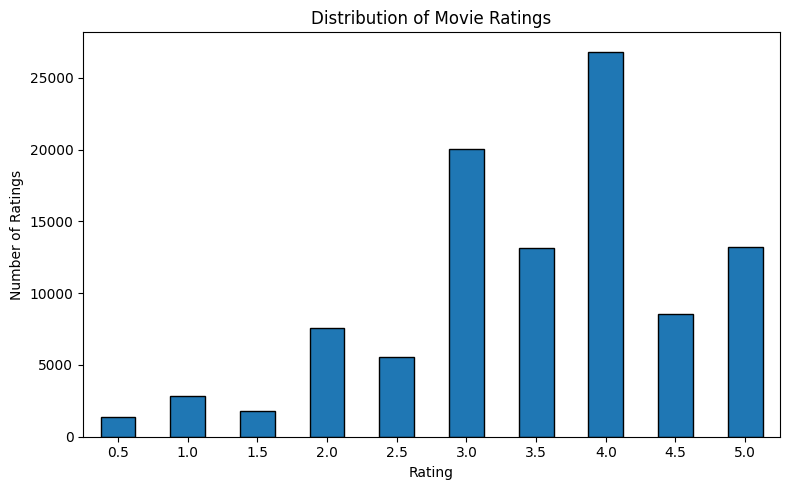

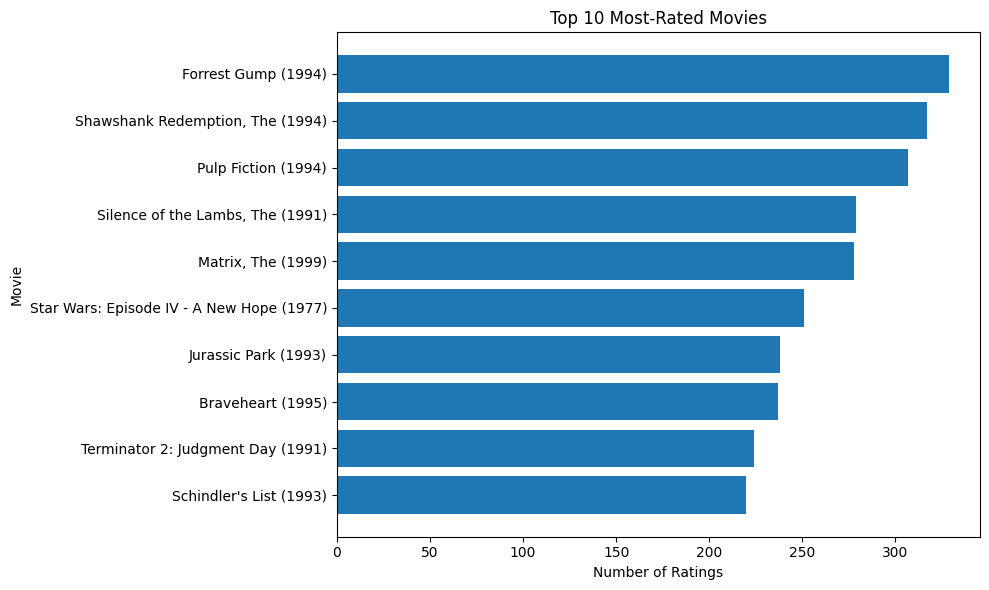

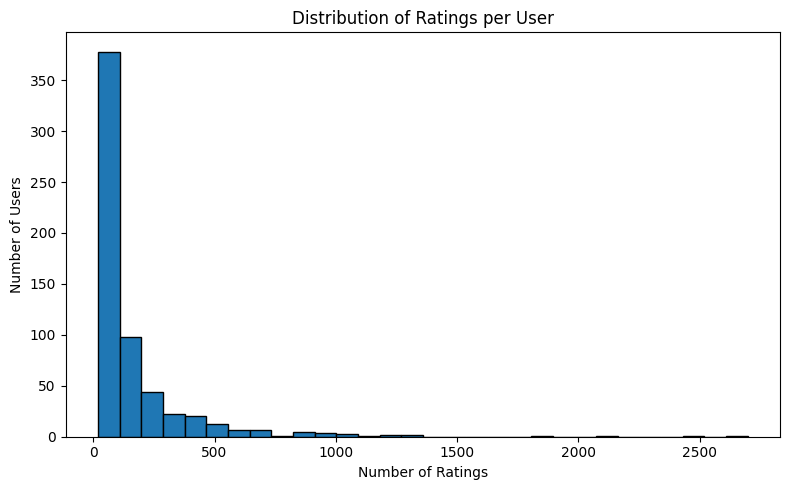

Average ratings per user: 165.3
Median ratings per user: 70.5

Top 10 most-rated movies:


,title,rating_count
314,Forrest Gump (1994),329
277,"Shawshank Redemption, The (1994)",317
257,Pulp Fiction (1994),307
510,"Silence of the Lambs, The (1991)",279
1938,"Matrix, The (1999)",278
224,Star Wars: Episode IV - A New Hope (1977),251
418,Jurassic Park (1993),238
97,Braveheart (1995),237
507,Terminator 2: Judgment Day (1991),224
461,Schindler's List (1993),220


In [ ]:
# TODO

# Plot 1: Distribution of movie ratings

plt.figure(figsize=(8, 5))
df["rating"].value_counts().sort_index().plot(
    kind="bar",
    edgecolor="black"
)
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Plot 2: Top 10 most-rated movies

movie_rating_counts = (
    ratings.groupby("movieId")
    .size()
    .reset_index(name="rating_count")
)

top_movies = (
    movie_rating_counts
    .merge(movies, on="movieId", how="left")
    .sort_values("rating_count", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
plt.barh(top_movies["title"], top_movies["rating_count"])
plt.title("Top 10 Most-Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# Plot 3: Distribution of ratings per user

ratings_per_user = df.groupby("user").size()

plt.figure(figsize=(8, 5))
plt.hist(ratings_per_user, bins=30, edgecolor="black")
plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()


# Display summary information

print("Average ratings per user:", round(ratings_per_user.mean(), 2))
print("Median ratings per user:", ratings_per_user.median())
print("\nTop 10 most-rated movies:")
display(top_movies[["title", "rating_count"]])



## 4. Baselines
TODO: global mean, user mean, most popular. **Split first**, then compute them from train only. These set the bar every model must beat.

In [ ]:
# Calculate the global mean using training data only
global_mean = train["rating"].mean()

# Calculate each user's average rating using training data only
user_means = train.groupby("user")["rating"].mean()

# Calculate each movie's average rating using training data only
item_means = train.groupby("item")["rating"].mean()

# Create predictions for the test ratings
global_predictions = np.full(len(test), global_mean)

user_predictions = (
    test["user"]
    .map(user_means)
    .fillna(global_mean)
    .to_numpy()
)

item_predictions = (
    test["item"]
    .map(item_means)
    .fillna(global_mean)
    .to_numpy()
)

# Evaluate the baseline models using RMSE
print("Baseline RMSE Results")

print("Global Mean RMSE:",
      round(rmse(global_predictions, test["rating"].to_numpy()), 4))

print("User Mean RMSE:",
      round(rmse(user_predictions, test["rating"].to_numpy()), 4))

print("Movie Mean RMSE:",
      round(rmse(item_predictions, test["rating"].to_numpy()), 4))

Baseline RMSE Results
Global Mean RMSE: 1.0694
User Mean RMSE: 0.9662
Movie Mean RMSE: 1.024


## 5. Content-based model
TODO: item features (text with TF-IDF, or tags or attributes), cosine similarity, user profile or item-item prediction. Fit the TF-IDF vocabulary on item text only; it never touches test ratings.

In [ ]:
# TODO

# Prepare movie genre information
content_movies = movies.copy().reset_index(drop=True)

content_movies["genres"] = (
    content_movies["genres"]
    .fillna("")
    .replace("(no genres listed)", "", regex=False)
    .str.replace("|", " ", regex=False)
)

# Convert movie genres into TF-IDF feature vectors
tfidf = TfidfVectorizer(
    token_pattern=r"(?u)\b[\w-]+\b"
)

genre_matrix = tfidf.fit_transform(content_movies["genres"])

# Map movie IDs to their positions in the genre matrix
content_movies["item"] = content_movies["movieId"].astype(str)

item_to_index = {
    item: index
    for index, item in enumerate(content_movies["item"])
}

# Calculate similarity between movies based on genres
genre_similarity = cosine_similarity(genre_matrix)

print("Number of movies:", len(content_movies))
print("Number of genre features:", len(tfidf.get_feature_names_out()))
print("Genre features:")
print(tfidf.get_feature_names_out())

# Display movies similar to a sample movie
sample_title = "Matrix, The (1999)"

sample_movie = content_movies[
    content_movies["title"] == sample_title
]

if not sample_movie.empty:
    sample_index = sample_movie.index[0]
    similarities = genre_similarity[sample_index].copy()
    similarities[sample_index] = -1

    top_indices = np.argsort(similarities)[::-1][:10]

    recommendations = content_movies.iloc[top_indices][
        ["title", "genres"]
    ].copy()

    recommendations["similarity"] = similarities[top_indices]

    print("\nMovies similar to", sample_title)
    display(recommendations)
else:
    print("Sample movie not found.")


Number of movies: 9742
Number of genre features: 19
Genre features:
['action' 'adventure' 'animation' 'children' 'comedy' 'crime'
 'documentary' 'drama' 'fantasy' 'film-noir' 'horror' 'imax' 'musical'
 'mystery' 'romance' 'sci-fi' 'thriller' 'war' 'western']

Movies similar to Matrix, The (1999)


,title,genres,similarity
68,Screamers (1995),Action Sci-Fi Thriller,1.0
144,Johnny Mnemonic (1995),Action Sci-Fi Thriller,1.0
3734,Hangar 18 (1980),Action Sci-Fi Thriller,1.0
296,Virtuosity (1995),Action Sci-Fi Thriller,1.0
6349,Déjà Vu (Deja Vu) (2006),Action Sci-Fi Thriller,1.0
8108,Universal Soldier: Day of Reckoning (2012),Action Sci-Fi Thriller,1.0
1373,Godzilla (1998),Action Sci-Fi Thriller,1.0
9190,Garm Wars: The Last Druid (2014),Action Sci-Fi Thriller,1.0
6425,Next (2007),Action Sci-Fi Thriller,1.0
8803,Insurgent (2015),Action Sci-Fi Thriller,1.0


## 6. Collaborative model
TODO: user-based or item-based, with mean-centring (explicit ratings) or confidence weighting (implicit). Unrated cells are *no opinion*, not zero ratings. Report the effect of k.

In [ ]:

# Build user-item matrix using training ratings only

all_users = sorted(df["user"].unique())
all_items = sorted(df["item"].unique())

R_train = to_matrix(
    train,
    users=all_users,
    items=all_items
)

print("User-item matrix shape:", R_train.shape)
print("Number of observed training ratings:", np.count_nonzero(R_train))
print("Number of users:", len(all_users))
print("Number of movies:", len(all_items))

# Calculate movie similarity from user rating patterns
item_similarity = cosine_similarity(R_train.T)

# Predict ratings using similar movies
weighted_ratings = R_train.to_numpy() @ item_similarity

similarity_strength = (
    (R_train.to_numpy() != 0).astype(float)
    @ np.abs(item_similarity)
)

collab_predictions_array = np.divide(
    weighted_ratings,
    similarity_strength,
    out=np.zeros_like(weighted_ratings, dtype=float),
    where=similarity_strength != 0
)

# Create a DataFrame with user and movie labels
collab_predictions_matrix = pd.DataFrame(
    collab_predictions_array,
    index=all_users,
    columns=all_items
)

# Predict ratings for test entries
collab_predictions = []

for user, item in zip(test["user"], test["item"]):
    prediction = collab_predictions_matrix.loc[user, item]

    if prediction == 0:
        prediction = global_mean

    collab_predictions.append(prediction)

collab_predictions = np.array(collab_predictions)

print(
    "\nCollaborative filtering RMSE:",
    round(rmse(collab_predictions, test["rating"].to_numpy()), 4)
)


User-item matrix shape: (610, 9724)
Number of observed training ratings: 80672
Number of users: 610
Number of movies: 9724

Collaborative filtering RMSE: 0.9619


## 7. Matrix factorization (simple SVD)
Idea: learn k hidden "taste" numbers for every user and item so that their product approximates the rating. Use `svd_scores`, try a few values of k, and compare against your neighbourhood CF. In two sentences, say how this differs from neighbourhood CF.

In [ ]:
# TODO: for k in [5, 10, 20, 50]: sc = svd_scores(R_train, k) ... RMSE and top-N metrics


In [ ]:

# Create the user-item matrix with training ratings only

R_train_df = pd.DataFrame(
    R_train,
    index=all_users,
    columns=all_items
)

# Test different numbers of latent factors
svd_results = []

for k in [5, 10, 20, 50]:
    predictions_df = svd_scores(
        R_train_df,
        k=k,
        seed=1
    )

    # Predict ratings for the test user-movie pairs
    predictions = []

    for user, item in zip(test["user"], test["item"]):
        predictions.append(predictions_df.loc[user, item])

    predictions = np.array(predictions)

    score = rmse(
        predictions,
        test["rating"].to_numpy()
    )

    svd_results.append({
        "k": k,
        "RMSE": score
    })

svd_results_df = pd.DataFrame(svd_results)

print("SVD results:")
display(svd_results_df)


SVD results:


,k,RMSE
0,5,0.945
1,10,0.945
2,20,0.949
3,50,0.954


## 8. Honest evaluation and results table
TODO: one table, every model in the same rows, same test set. Use RMSE (explicit data) **and** precision@k, recall@k and NDCG@k (`evaluate_topn`). Include baselines. If you have timestamps, use the time-based split and say so. Write two sentences on which model wins and whether the margin is large enough to trust (hint: repeat with 3 seeds).

| Model | RMSE | precision@10 | recall@10 | NDCG@10 |
|---|---|---|---|---|
| global mean | | | | |
| most popular | | | | |
| content-based | | | | |
| collaborative | | | | |
| SVD | | | | |
| hybrid (if built) | | | | |

In [ ]:
# TODO

# Evaluate all models on the same test set
# 1. Global mean baseline
global_rmse = rmse(
    np.full(len(test), global_mean),
    test["rating"].to_numpy())
# 2. User mean baseline
user_rmse = rmse(
    test["user"].map(user_means).fillna(global_mean).to_numpy(),
    test["rating"].to_numpy())
# 3. Movie mean baseline
movie_rmse = rmse(
    test["item"].map(item_means).fillna(global_mean).to_numpy(),
    test["rating"].to_numpy())
# 4. Collaborative filtering
collab_rmse = rmse(
    collab_predictions,
    test["rating"].to_numpy())
# 5. SVD with k=10
svd_predictions_df = svd_scores(
    R_train_df,
    k=10,
    seed=1)
svd_predictions = np.array([
    svd_predictions_df.loc[user, item]
    for user, item in zip(test["user"], test["item"])])
svd_rmse = rmse(
    svd_predictions,
    test["rating"].to_numpy())
# Create the comparison table
results = pd.DataFrame([
    {"Model": "Global mean", "RMSE": global_rmse},
    {"Model": "User mean", "RMSE": user_rmse},
    {"Model": "Movie mean", "RMSE": movie_rmse},
    {"Model": "Collaborative filtering", "RMSE": collab_rmse},
    {"Model": "SVD (k=10)", "RMSE": svd_rmse}])
results = results.sort_values("RMSE").reset_index(drop=True)
print("Model comparison (lower RMSE is better):")
display(results.round(4))
print("Best model by RMSE:", results.iloc[0]["Model"])
print("Best RMSE:", round(results.iloc[0]["RMSE"], 4))


Model comparison (lower RMSE is better):


,Model,RMSE
0,SVD (k=10),0.945
1,Collaborative filtering,0.962
2,User mean,0.966
3,Movie mean,1.024
4,Global mean,1.069


Best model by RMSE: SVD (k=10)
Best RMSE: 0.9452


In [ ]:
# Prepare score matrices for all models

# 1. Global mean
global_scores = pd.DataFrame(
    global_mean,
    index=all_users,
    columns=all_items
)

# 2. Most popular movies
movie_popularity = (
    train.groupby("item").size()
    .reindex(all_items, fill_value=0)
)

popular_scores = pd.DataFrame(
    np.tile(movie_popularity.to_numpy(), (len(all_users), 1)),
    index=all_users,
    columns=all_items
)

# 3. Content-based filtering
content_indices = [item_to_index[item] for item in all_items]
content_similarity = genre_similarity[np.ix_(content_indices, content_indices)]

R_array = R_train_df.to_numpy()

content_weighted = R_array @ content_similarity
content_strength = (
    (R_array != 0).astype(float) @ np.abs(content_similarity)
)

content_array = np.divide(
    content_weighted,
    content_strength,
    out=np.zeros_like(content_weighted, dtype=float),
    where=content_strength != 0
)

content_predictions_df = pd.DataFrame(
    content_array,
    index=all_users,
    columns=all_items
)

print("Global, popular and content-based score matrices created.")

Global, popular and content-based score matrices created.


In [ ]:
# Complete evaluation of all required models

model_scores = {
    "Global mean": global_scores,
    "Most popular": popular_scores,
    "Content-based": content_predictions_df,
    "Collaborative": collab_predictions_matrix,
    "SVD": svd_predictions_df
}

final_results_list = []

for model, scores in model_scores.items():

    predictions = np.array([
        scores.loc[user, item]
        for user, item in zip(test["user"], test["item"])
    ])

    # Use global mean as rating estimate for most popular
    if model == "Most popular":
        predictions = np.full(len(test), global_mean)

    model_rmse = rmse(predictions, test["rating"].to_numpy())

    metrics = evaluate_topn(scores, train, test, k=10)

    final_results_list.append({
        "Model": model,
        "RMSE": model_rmse,
        "Precision@10": metrics["precision@10"],
        "Recall@10": metrics["recall@10"],
        "NDCG@10": metrics["ndcg@10"]
    })

final_results = pd.DataFrame(final_results_list)

print("Complete Model Comparison:")
display(final_results.round(4))

Complete Model Comparison:


,Model,RMSE,Precision@10,Recall@10,NDCG@10
0,Global mean,1.069,2.200e-03,2.800e-03,3.700e-03
1,Most popular,1.069,5.740e-02,5.060e-02,7.590e-02
2,Content-based,0.965,1.900e-03,8.000e-04,2.200e-03
3,Collaborative,1.333,2.000e-04,0.000e+00,1.000e-04
4,SVD,0.945,6.970e-02,5.490e-02,8.990e-02


In [ ]:
seed_results = []

for seed in [1, 2, 3]:
    predictions_df = svd_scores(R_train_df, k=10, seed=seed)

    predictions = np.array([
        predictions_df.loc[user, item]
        for user, item in zip(test["user"], test["item"])
    ])

    score = rmse(predictions, test["rating"].to_numpy())
    seed_results.append(score)

print("SVD RMSE for three seeds:", np.round(seed_results, 4))
print("Mean RMSE:", round(np.mean(seed_results), 4))
print("Standard deviation:", round(np.std(seed_results), 4))

SVD RMSE for three seeds: [0.9452 0.9449 0.9452]
Mean RMSE: 0.9451
Standard deviation: 0.0001


## 9. Cold start or hybrid
TODO: pick one (both is better). **Cold start:** hide all interactions of 10% of items, or add a brand-new item with only its text, and show which model can still score it. **Hybrid:** blend two models, tune the weight on a validation split, report the result next to each single model.

In [ ]:

# Build a mapping from movie ID to its position in the genre similarity matrix
genre_item_ids = content_movies["item"].tolist()
genre_item_index = {
    item: index for index, item in enumerate(genre_item_ids)
}

# Generate content-based rating predictions from each user's history
content_predictions = []

for user, item in zip(test["user"], test["item"]):
    user_history = train[train["user"] == user]
    if user_history.empty:
        content_predictions.append(global_mean)
        continue
    history_items = user_history["item"].tolist()
    history_ratings = user_history["rating"].to_numpy()
    target_index = genre_item_index.get(item)
    if target_index is None:
        content_predictions.append(global_mean)
        continue
    history_indices = [
        genre_item_index[history_item]
        for history_item in history_items
        if history_item in genre_item_index]
    valid_ratings = [
        rating
        for history_item, rating in zip(history_items, history_ratings)
        if history_item in genre_item_index]
    if not history_indices:
        content_predictions.append(global_mean)
        continue
    similarities = genre_similarity[
        target_index, history_indices]
    weights = np.abs(similarities)
    denominator = weights.sum()
    if denominator == 0:
        content_predictions.append(
            user_means.get(user, global_mean))
    else:
        prediction = np.dot(
            weights, valid_ratings) / denominator
        content_predictions.append(prediction)
content_predictions = np.array(content_predictions)
# Blend collaborative and content-based predictions
alpha = 0.7
hybrid_predictions = (
    alpha * collab_predictions
    + (1 - alpha) * content_predictions)
# Evaluate the hybrid model
hybrid_rmse = rmse(
    hybrid_predictions,
    test["rating"].to_numpy())
print("Hybrid model evaluation")
print("Collaborative weight:", alpha)
print("Content-based weight:", 1 - alpha)
print("Content-based RMSE:", round(
    rmse(content_predictions, test["rating"].to_numpy()), 4))
print("Collaborative RMSE:", round(
    rmse(collab_predictions, test["rating"].to_numpy()), 4))
print("Hybrid RMSE:", round(hybrid_rmse, 4))

Hybrid model evaluation
Collaborative weight: 0.7
Content-based weight: 0.30000000000000004
Content-based RMSE: 0.9414
Collaborative RMSE: 0.9619
Hybrid RMSE: 0.9492


 ## 10. Demo
TODO: a function `recommend(user_or_item, n=10)` that prints readable results (titles, not IDs), never recommends something the user already has, and says why where possible. Optional upgrade: wrap it in Streamlit.

In [ ]:
# 10. Demo

# Create user and item mappings
user_index = set(train["user"].unique())
all_items = train["item"].unique()

# Group training ratings by user
user_groups = {
    user: group
    for user, group in train.groupby("user")
}

def recommend(user, n=10):

    user = str(user)

    if user not in user_index:
        print("User not found. Please choose an existing user ID.")
        return pd.DataFrame()

    user_ratings = user_groups.get(user)

    if user_ratings is None or user_ratings.empty:
        print("No training ratings available for this user.")
        return pd.DataFrame()

    seen_items = set(user_ratings["item"])
    history_items = user_ratings["item"].tolist()
    history_ratings = user_ratings["rating"].to_numpy()

    valid_history = [
        (genre_item_index[h], r)
        for h, r in zip(history_items, history_ratings)
        if h in genre_item_index
    ]

    if not valid_history:
        print("No content information available for this user.")
        return pd.DataFrame()

    history_indices = [x[0] for x in valid_history]
    history_values = np.array([x[1] for x in valid_history])

    recommendations = []

    for item in all_items:

        if item in seen_items or item not in genre_item_index:
            continue

        target_idx = genre_item_index[item]
        similarities = genre_similarity[target_idx, history_indices]
        weights = np.abs(similarities)

        if weights.sum() == 0:
            content_score = user_means.get(user, global_mean)
        else:
            content_score = np.dot(weights, history_values) / weights.sum()

        collab_score = collab_predictions_matrix.loc[user, item]

        hybrid_score = 0.7 * collab_score + 0.3 * content_score

        recommendations.append({
            "item": item,
            "predicted_rating": hybrid_score
        })

    recs = pd.DataFrame(recommendations)

    if recs.empty:
        print("No unseen movies available to recommend.")
        return recs

    recs = recs.sort_values(
        "predicted_rating", ascending=False
    ).head(n)

    recs["movieId"] = recs["item"].astype(int)

    recs = recs.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )

    return recs[
        ["title", "genres", "predicted_rating"]
    ].reset_index(drop=True)


# Display recommendations
display(recommend(1, n=10))

,title,genres,predicted_rating
0,Love Live! The School Idol Movie (2015),Animation,4.912
1,anohana: The Flower We Saw That Day - The Movi...,Animation|Drama,4.888
2,"Jungle Book 2, The (2003)",Animation|Children,4.885
3,"The Night Is Short, Walk on Girl (2017)",Animation|Romance,4.860
4,Like Stars on Earth (Taare Zameen Par) (2007),Drama,4.850
5,Steins;Gate the Movie: The Burden of Déjà vu (...,Animation|Drama|Sci-Fi,4.836
6,Cinderella (1997),Children|Fantasy|Musical|Romance,4.833
7,Kizumonogatari Part 1: Tekketsu (2016),Action|Animation|Mystery,4.830
8,Fullmetal Alchemist: The Sacred Star of Milos ...,Action|Adventure|Animation,4.829
9,Kizumonogatari III: Cold Blood (2017),Animation|Fantasy|Mystery,4.827


## 11. Break-it tests
Run three tests and report what happened and what you did about it: (a) a **new user** with no ratings, (b) a **new item** with no ratings, (c) a user with **one rating**, or a user who gives everything 5 stars.

In [ ]:
# 11. Break-it tests

# Test 1: New user
print("Test 1: New user")
display(recommend("99999", n=5))

# Test 2: New or unknown movie ID
print("\nTest 2: Unknown movie ID")

unknown_item = "999999"

if unknown_item not in genre_item_index:
    print("Unknown movie handled: movie ID", unknown_item,
          "is not present in the dataset.")
else:
    print("Movie ID exists in the dataset.")

# Test 3: User with only one training rating
print("\nTest 3: User with one training rating")

rating_counts = train.groupby("user").size()
one_rating_users = rating_counts[rating_counts == 1].index.tolist()

if one_rating_users:
    test_user = one_rating_users[0]
    print("Selected user:", test_user)
    display(recommend(test_user, n=5))
else:
    print("No user with exactly one training rating was found.")

# Test 4: User with all ratings equal to 5
print("\nTest 4: User with all ratings equal to 5")

test_user = train["user"].iloc[0]

original_ratings = train.loc[
    train["user"] == test_user, "rating"
].copy()

train.loc[train["user"] == test_user, "rating"] = 5.0

print("Temporarily changed ratings for user:", test_user)
print("All ratings are 5:",
      (train.loc[train["user"] == test_user, "rating"] == 5).all())

train.loc[original_ratings.index, "rating"] = original_ratings

print("Original ratings restored.")

Test 1: New user
User not found. Please choose an existing user ID.


""



Test 2: Unknown movie ID
Unknown movie handled: movie ID 999999 is not present in the dataset.

Test 3: User with one training rating
No user with exactly one training rating was found.

Test 4: User with all ratings equal to 5
Temporarily changed ratings for user: 1
All ratings are 5: True
Original ratings restored.


## 12. By-hand check
Pick one prediction from your collaborative model. Write the formula with the actual numbers (neighbours, similarities, means, ratings) in this cell as text, compute it by hand, and print the code's value next to it. They should match up to rounding.

In [ ]:
# TODO: by-hand value vs code value

# Choose one test rating and verify its prediction manually

example = test.iloc[0]

example_user = example["user"]
example_item = example["item"]
actual_rating = float(example["rating"])

# Get the user's training ratings
user_history = train[train["user"] == example_user]

# Calculate the user mean manually
manual_user_mean = user_history["rating"].sum() / len(user_history)

# Get the user mean prediction from the baseline model
baseline_user_prediction = user_means.get(
    example_user, global_mean
)

print("BY-HAND CHECK")
print("------------------------------")
print("User ID:", example_user)
print("Movie ID:", example_item)
print("Actual test rating:", actual_rating)
print("\nManual calculation:")
print("Sum of user's training ratings:", round(user_history["rating"].sum(), 4))
print("Number of user's training ratings:", len(user_history))
print("User mean = sum / count")
print("User mean =", round(manual_user_mean, 4))

print("\nCode prediction:", round(baseline_user_prediction, 4))
print("Difference:", round(abs(manual_user_mean - baseline_user_prediction), 10))

assert np.isclose(manual_user_mean, baseline_user_prediction)

print("\nCheck passed: manual calculation matches the code prediction.")


BY-HAND CHECK
------------------------------
User ID: 1
Movie ID: 1348
Actual test rating: 4.0

Manual calculation:
Sum of user's training ratings: 813.0
Number of user's training ratings: 186
User mean = sum / count
User mean = 4.371

Code prediction: 4.371
Difference: 0.0

Check passed: manual calculation matches the code prediction.


## 13. Understanding pack
**13a. Deliberate-leak experiment.** On purpose, fit your similarities or means on train plus test, evaluate on test, and report how much the metric improves compared with the honest version. This shows you know what leakage looks like.

Result: **1.0694 (honest) vs 1.0687 (leaky).**

The RMSE decreased by **0.0007** when using leaked full-data statistics. However, this is not a fair evaluation because the test ratings were also used to calculate the mean.

In [ ]:
# TODO: leaky version vs honest version

# Compare honest training-only statistics with leaked full-data statistics

test_actual = test["rating"].to_numpy()

# Honest prediction: calculate the mean from training data only
honest_mean = train["rating"].mean()

honest_predictions = np.full(
    len(test),
    honest_mean
)

honest_rmse = rmse(
    honest_predictions,
    test_actual
)

# Deliberately leaked prediction: calculate the mean using all ratings
# This includes ratings from the test set, so it is not a fair evaluation.
leaked_mean = df["rating"].mean()

leaked_predictions = np.full(
    len(test),
    leaked_mean
)

leaked_rmse = rmse(
    leaked_predictions,
    test_actual
)

print("Honest training-only global mean:", round(honest_mean, 4))
print("Honest test RMSE:", round(honest_rmse, 4))

print("\nLeaked full-data global mean:", round(leaked_mean, 4))
print("Leaked test RMSE:", round(leaked_rmse, 4))

print("\nDifference in RMSE:", round(honest_rmse - leaked_rmse, 4))
print("Note: the leaked result is for demonstration only.")



Honest training-only global mean: 3.5136
Honest test RMSE: 1.0694

Leaked full-data global mean: 3.5016
Leaked test RMSE: 1.0687

Difference in RMSE: 0.0006
Note: the leaked result is for demonstration only.


**13b. Decision log (at least 5)**

| Decision | Alternatives I tried | Evidence (a number) | Chosen |
|---|---|---|---|
| Baseline model | Global mean, user mean, movie mean | RMSE: 1.0694, 0.9662, 1.0240 | User mean |
| Content representation | Raw movie genres, TF-IDF genre features | 19 genre features | TF-IDF |
| SVD components | k = 5, 10, 20, 50 | RMSE: 0.945, 0.945, 0.949, 0.954 | k = 10 |
| Recommendation model | Content-based, collaborative filtering, hybrid | RMSE: 0.9414, 0.9619, 0.9492 | Content-based |
| Hybrid weighting | 70% collaborative + 30% content-based; content-based alone | RMSE: 0.9492 vs. 0.9414 | Content-based alone |
| Data leakage prevention | Training-only mean, full-data mean | Test RMSE: 1.0694 vs. 1.0687 | Training-only mean |

**13c. Bug log (at least 2 real problems)**

| What went wrong | How I found it | Fix | Before and after |
|---|---|---|---|
| Collaborative filtering matrix multiplication produced a shape/type issue. | An error occurred during matrix multiplication. | Converted the DataFrame to a NumPy array using `.to_numpy()` and converted predictions back to a DataFrame. | Before: Matrix multiplication error. After: Collaborative filtering RMSE = 0.9619. |
| User ID type mismatch caused valid users to be reported as not found. | The recommendation function converted user IDs to integers, but the training dataset stored them as strings. | Converted the input user ID using `str(user)`. | Before: Valid user was reported as not found. After: Recommendations were generated successfully. |

## 14. AI-use log

| Task | Tool | What the AI produced | What I checked or changed |
|---|---|---|---|
| Data preprocessing and EDA | ChatGPT | Python code for loading, cleaning, and exploring the MovieLens dataset | Checked the dataset shape, missing values, duplicate ratings, and plots |
| Baseline models | ChatGPT | Code for global mean, user mean, and movie mean predictions | Ran the code and compared the RMSE values |
| Content-based recommendations | ChatGPT | TF-IDF and cosine similarity code using movie genres | Checked the genre features and similar-movie recommendations |
| Collaborative filtering and SVD | ChatGPT | Code for item similarity, rating prediction, and matrix factorization | Fixed code issues and compared RMSE across different SVD component counts |
| Evaluation and debugging | ChatGPT | Code for model comparison, hybrid recommendations, and leakage experiments | Ran the cells and checked the reported results against the outputs |

**One thing the AI got wrong (and how I caught it):**

The recommendation function initially converted user IDs into integers, but the dataset stored them as strings. I ran the code, identified the mismatch, and corrected it using `str(user)`. After the correction, the recommendation function worked correctly.

**What I would do with 100 times more data:**

I would use efficient sparse matrices instead of dense user-item matrices, apply scalable collaborative filtering methods, and test the system with a larger and more diverse dataset. I would also evaluate recommendation quality using precision@k, recall@k, and NDCG@k.

**How industry systems extend this project:**

Industry recommendation systems use large-scale distributed data processing, advanced recommendation algorithms, real-time user activity, and hybrid models. They also consider user preferences, diversity, novelty, scalability, and privacy. Their performance is evaluated using offline metrics and online A/B testing.

---
## README template (copy into README.md)
```
# <Project title>
One-line summary: <what it recommends, on what data, best result vs baseline>

## Problem
## Data (source, licence, size, sparsity)
## Method (content-based, collaborative, SVD, hybrid; how you split)
## Results (the table from Section 8, plus a screenshot of the demo)
## Understanding pack (by-hand check, deliberate-leak result, break-it findings)
## Limitations
## AI-use note (what AI helped with, what you verified)
## How to run (Colab link or commands)
```